# 02 · Procesamiento y normalización de variables

Parte de la población definida en el notebook 01 (**4.719 primeros créditos de moto de clientes independientes**). Para cada variable se muestra el valor **crudo** del registro C-0, el problema encontrado y el valor **normalizado**. Al final:

- se arma la base del modelo;
- se verifica que coincida con la del script `src/limpieza.py`;
- se describe la población con resultado a 6 meses (2.908 créditos; los pagos anticipados cuentan como buenos pagadores).

**Principio:** aquí solo se hacen correcciones que no dependen de la variable objetivo. Lo que sí depende de ella (agrupar categorías raras y codificar las ciudades por tasa de mora) se hace dentro del entrenamiento, para no filtrar información de la muestra de prueba.

**Política de variables:** el sexo no entra al modelo, se usa solo para auditar la equidad; el código de distribuidor tampoco entra, solo se usa para construir su volumen; se agregan las variables del lugar de compra (sección 4.3). La sección 5 resume qué variables pueden entrar al modelo y por qué se excluyen las demás.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import limpieza as L

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.3f}".format)

df = pd.read_parquet(RAIZ / "datos" / "cartera.parquet")
panel, c0, embudo, ultimo_corte = L.filtrar_poblacion(df)
print(f"Población: {len(c0):,} créditos (registro C-0 de cada uno)")

def antes_despues(crudo, limpio, nombre):
    t = pd.crosstab(crudo.fillna("<vacío>").astype(str), limpio.fillna("<faltante>").astype(str))
    t.index.name, t.columns.name = f"{nombre} (crudo)", "normalizado"
    return t

Población: 4,719 créditos (registro C-0 de cada uno)


## 1. Normalización general de texto

Todas las variables de texto pasan por `normalizar_texto`:
- se convierten a mayúsculas y se les quitan las tildes;
- se eliminan el apóstrofo de Excel y los espacios dobles;
- los faltantes escritos de distintas formas (`None`, `Sin datos`, `?`, `-`, vacío) se unifican.

In [2]:
ejemplos = pd.Series(["Medellin", "MEDELLIN", " medellín ", "Sin datos", "?", "'0141", "Maestría", "SECRETARIADO  CONTABLE"])
pd.DataFrame({"crudo": ejemplos, "normalizado": L.normalizar_texto(ejemplos)})

,crudo,normalizado
0,Medellin,MEDELLIN
1,MEDELLIN,MEDELLIN
2,medellín,MEDELLIN
3,Sin datos,NaN
4,?,NaN
5,'0141,0141
6,Maestría,MAESTRIA
7,SECRETARIADO CONTABLE,SECRETARIADO CONTABLE


## 2. Variables sociodemográficas

### 2.1 Sexo, estado civil y nivel de estudio

In [3]:
estado_civil = L.normalizar_texto(c0["Estado Civil"]).str.replace(r"\(A\)", "", regex=True).str.strip()
nivel = L.normalizar_texto(c0["Nivel Estudio"]).replace({"MAESTRIA": "POSTGRADO"})
display(antes_despues(c0["Sexo"], L.normalizar_texto(c0["Sexo"]), "Sexo"))
display(antes_despues(c0["Estado Civil"], estado_civil, "Estado civil"))
display(antes_despues(c0["Nivel Estudio"], nivel, "Nivel de estudio"))

normalizado,F,M
Sexo (crudo),,
F,1865,0
M,0,2854


normalizado,<faltante>,CASADO,SEPARADO,SOLTERO,UNION LIBRE,VIUDO
Estado civil (crudo),,,,,,
<vacío>,5,0,0,0,0,0
Casado(a),0,924,0,0,0,0
Separado(a),0,0,34,0,0,0
Soltero(a),0,0,0,2552,0,0
Union libre,0,0,0,0,1186,0
Viudo(a),0,0,0,0,0,18


normalizado,BACHILLER,POSTGRADO,PREGRADO,PRIMARIA,SIN ESTUDIO
Nivel de estudio (crudo),,,,,
Bachiller,2103,0,0,0,0
Maestría,0,121,0,0,0
Postgrado,0,663,0,0,0
Pregrado,0,0,1703,0,0
Primaria,0,0,0,127,0
Sin estudio,0,0,0,0,2


- **Estado civil:** se elimina el sufijo `(a)`.
- **Nivel de estudio:** Maestría tiene muy pocos casos (y tildes corruptas en la fuente), así que se agrupa con Postgrado.

### 2.2 Estrato

In [4]:
estrato = pd.to_numeric(L.normalizar_texto(c0["Estrato"]), errors="coerce")
display(estrato.value_counts(dropna=False).sort_index().rename("créditos").to_frame().T)
validos = estrato.where(estrato.between(1, 6))
anio_des = L.fecha_excel(c0["Fecha desembolso"]).dt.year
moda_estrato = validos[anio_des < 2025].mode().iloc[0]
print(f"Estrato 7 (no existe en Colombia; error de digitación): {(estrato == 7).sum()} casos "
      f"-> moda de 2023-2024 ({moda_estrato:.0f})")

Estrato,1,2,3,4,5,6,7
créditos,7,433,1480,2011,577,161,50


Estrato 7 (no existe en Colombia; error de digitación): 50 casos -> moda de 2023-2024 (4)


### 2.3 Personas a cargo

In [5]:
cargo = pd.to_numeric(L.normalizar_texto(c0["Personas A Cargo"]), errors="coerce")
display(antes_despues(c0["Personas A Cargo"], cargo.where(cargo <= 8), "Personas a cargo"))

normalizado,0.0,1.0,2.0,3.0,4.0,5.0,6.0,<faltante>
Personas a cargo (crudo),,,,,,,,
0,3272,0,0,0,0,0,0,0
00,2,0,0,0,0,0,0,0
02,0,0,1,0,0,0,0,0
1,0,919,0,0,0,0,0,0
10,0,0,0,0,0,0,0,1
14,0,0,0,0,0,0,0,1
2,0,0,418,0,0,0,0,0
3,0,0,0,80,0,0,0,0
4,0,0,0,0,20,0,0,0


`00`, `01` y `02` se leen como 0, 1 y 2. Los valores 10 y 14 son improbables para un independiente que solicita una moto y se tratan como error de digitación (faltante).

### 2.4 Edad

In [6]:
display(c0["Age"].describe().to_frame("edad").T)
print("Fuera de 18-90 años:", (~c0["Age"].between(18, 90)).sum())

,count,mean,std,min,25%,50%,75%,max
edad,"4,719.000",36.581,10.878,18.000,28.000,35.000,43.000,75.000


Fuera de 18-90 años: 0


### 2.5 Tipo de independiente

In [7]:
c0["SECTOR_ECONOMICO"].value_counts().rename("créditos").to_frame()

,créditos
SECTOR_ECONOMICO,
formal_independent,3882
informal_independent,837


Se conservan los dos tipos. Se crea `independiente_informal` (1 = informal), porque su riesgo es distinto (sección 6).

### 2.6 Ciudad

In [8]:
ciudad = L.normalizar_texto(c0["Ciudad"])
print(f"Ciudades distintas: {c0['Ciudad'].nunique()} crudas -> {ciudad.nunique()} normalizadas")
fusionadas = (pd.DataFrame({"crudo": c0["Ciudad"], "normalizado": ciudad}).drop_duplicates()
              .groupby("normalizado")["crudo"].agg(list).loc[lambda s: s.str.len() > 1])
display(fusionadas.head(10).to_frame("formas crudas unificadas"))
print(f"Ciudades con menos de 20 créditos: {(ciudad.value_counts() < 20).sum()} (se agrupan dentro del entrenamiento)")

Ciudades distintas: 349 crudas -> 341 normalizadas


,formas crudas unificadas
normalizado,
BOGOTA,"[Bogota, BOGOTA]"
BUCARAMANGA,"[Bucaramanga, BUCARAMANGA]"
IBAGUE,"[IBAGUE, IBAGUÉ]"
ITAGUI,"[ITAGUI, ITAGÜI]"
LA ESTRELLA,"[La Estrella, LA ESTRELLA]"
MEDELLIN,"[Medellin, MEDELLIN]"
PEREIRA,"[Pereira, PEREIRA]"
SABANETA,"[Sabaneta, SABANETA]"


Ciudades con menos de 20 créditos: 303 (se agrupan dentro del entrenamiento)


## 3. Variables de producto

### 3.1 Modelo de moto → familia y tipo de uso

`TIPO_MOTO` escribe el mismo modelo de muchas formas (código de fábrica, nombre comercial, versión). Se agrupa en **familia comercial** y en **tipo de uso**. Por confidencialidad, cada familia se muestra con su tipo de uso y una letra según su frecuencia (A = la más frecuente), sin las escrituras originales del modelo.

In [9]:
tipo = L.normalizar_texto(c0["TIPO_MOTO"])
familia = tipo.map(L.familia_moto).rename("familia")
uso = familia.map(L.TIPO_USO).fillna("OTRA")
print(f"{c0['TIPO_MOTO'].nunique()} escrituras distintas -> {familia.nunique()} familias -> {uso.nunique()} tipos de uso")
# Por confidencialidad, cada familia se muestra con su tipo de uso y una letra según su frecuencia (A = la más frecuente)
etiqueta = L.etiquetas_familia(pd.DataFrame({"familia_moto": familia, "tipo_uso_moto": uso}))
mapeo = (pd.DataFrame({"tipo de uso": uso, "familia": familia.map(etiqueta), "escritura": c0["TIPO_MOTO"]})
         .groupby(["tipo de uso", "familia"]).agg(escrituras=("escritura", "nunique"), créditos=("escritura", "size")))
mapeo

50 escrituras distintas -> 18 familias -> 5 tipos de uso


escrituras  créditos
tipo de uso     familia                                    
ATV             Cuatrimoto A                    1         1
DOBLE_PROPOSITO Doble propósito A               3       580
                Doble propósito B               2       182
                Doble propósito C               2       158
NAKED_SPORT     Deportiva A                     3       369
                Deportiva B                     5       342
                Deportiva C                     4       126
                Deportiva D                     6        60
                Deportiva E                     3         8
                Deportiva F                     3         6
SCOOTER         Scooter A                       5      1997
                Scooter B                       1       274
                Scooter C                       1        51
                Scooter D                       1         4
URBANA_TRABAJO  Urbana y de trabajo A           4       286
                Urbana y de trabajo B           2       182
                Urbana y de trabajo C           2        75
                Urbana y de trabajo D           2        18

### 3.2 Cilindraje

In [10]:
cil = pd.to_numeric(L.normalizar_texto(c0["Cilindraje"]), errors="coerce")
print("Valores crudos:", c0["Cilindraje"].value_counts(dropna=False).to_dict())
print(f"Sin dato: {cil.isna().sum()} -> se imputan con el cilindraje más frecuente de su familia de moto")
pd.crosstab(familia.map(etiqueta), cil.fillna(-1).astype(int).replace(-1, "sin dato"))

Valores crudos: {'155': 2645, '149': 1038, '249': 276, '124': 190, '114': 172, 'Sin datos': 124, '113.7': 104, '110': 74, None: 45, '150': 32, '321': 8, '890': 5, '292': 4, '421': 1, '65': 1}
Sin dato: 169 -> se imputan con el cilindraje más frecuente de su familia de moto


Cilindraje,65,110,113,114,124,149,150,155,249,292,321,421,890,sin dato
familia,,,,,,,,,,,,,,
Cuatrimoto A,0,0,0,0,0,0,0,0,0,0,0,1,0,0
Deportiva A,0,0,0,0,0,0,0,356,0,0,0,0,0,13
Deportiva B,0,0,0,0,0,337,0,0,0,0,0,0,0,5
Deportiva C,0,0,0,0,0,0,0,0,123,0,0,0,0,3
Deportiva D,0,0,0,0,0,0,0,60,0,0,0,0,0,0
Deportiva E,0,0,0,0,0,0,0,0,0,0,8,0,0,0
Deportiva F,1,0,0,0,0,0,0,0,0,0,0,0,5,0
Doble propósito A,0,0,0,0,0,531,32,0,0,0,0,0,0,17
Doble propósito B,0,0,0,0,172,0,0,0,0,0,0,0,0,10


### 3.3 Precio de la moto

In [11]:
display(c0["Product_Price"].describe(percentiles=[.01, .05, .5, .95, .99]).to_frame("precio").T)
familia_precio = c0.groupby(familia.map(etiqueta))["Product_Price"].median().sort_values().rename("precio mediano")
familia_precio.map("{:,.0f}".format).to_frame().T

,count,mean,std,min,1%,5%,50%,95%,99%,max
precio,"4,719.000","14,462,177.601","3,906,981.136","6,200,000.000","6,800,000.000","8,400,000.000","15,500,000.000","16,500,000.000","25,500,000.000","67,000,000.000"


familia,Urbana y de trabajo C,Urbana y de trabajo A,Urbana y de trabajo D,Urbana y de trabajo B,Doble propósito B,Deportiva B,Scooter C,Scooter B,Doble propósito A,Deportiva C,Deportiva D,Deportiva A,Scooter A,Doble propósito C,Deportiva E,Scooter D,Cuatrimoto A,Deportiva F
precio mediano,"6,600,000","8,400,000","8,400,000","9,500,000","10,200,000","11,700,000","12,500,000","12,700,000","12,900,000","14,800,000","15,400,000","15,500,000","16,500,000","25,500,000","29,500,000","34,000,000","49,680,000","57,500,000"


El precio es una característica **del producto** (precio de lista de la moto), no del crédito: es una de las variables de producto permitidas. No hay que confundirlo con el monto financiado ni con la cuota inicial, que están excluidos por ser condiciones del crédito.

### 3.4 A nombre de quién queda la moto

In [12]:
L.normalizar_texto(c0["Propietario Moto"]).value_counts().rename("créditos").to_frame()

,créditos
Propietario Moto,
CLIENTE,4195
OTRO,524


## 4. Variables del lugar de compra

### 4.1 Zona homologada

El código de zona original cambia de significado entre años (ver notebook 01, sección 5). Se asigna a cada ciudad la zona que tuvo en **2025**, calculada con todos los créditos de moto a personas desembolsados en 2025 y excluyendo los códigos "SIN ASIGNAR".

In [13]:
motos_c0 = df[(df["Tipo"] == "01CR") & (df["Productos"] == "Motocicletas") & (df["Mes_Cosecha"] == 0)]
mapa = L.zona_homologada(motos_c0)
zona_h = ciudad.map(mapa)
anio = L.fecha_excel(c0["Fecha desembolso"]).dt.year
print(f"Ciudades en el mapa: {len(mapa)} | créditos sin zona asignable: {zona_h.isna().sum()}")
display(pd.crosstab(L.codigo_entero(c0["Zona"]), anio, normalize="columns").rename_axis("zona ORIGINAL").style.format("{:.0%}"))
display(pd.crosstab(zona_h.fillna("SIN ZONA"), anio, normalize="columns").rename_axis("zona HOMOLOGADA").style.format("{:.0%}"))

Ciudades en el mapa: 541 | créditos sin zona asignable: 37


Fecha desembolso,2023,2024,2025
zona ORIGINAL,,,
1,40%,17%,1%
2,0%,11%,24%
3,20%,15%,13%
4,2%,15%,13%
5,11%,17%,28%
6,25%,19%,11%
7,0%,3%,2%
8,0%,2%,8%


Fecha desembolso,2023,2024,2025
zona HOMOLOGADA,,,
SIN ZONA,2%,2%,0%
Z02 SANTANDERES/ CESAR/ BOLIVAR/ ATLANTICO,1%,12%,24%
Z03 VALLE/ CAUCA/ HUILA/ NARINO,20%,15%,13%
Z04 EJE CAFETERO/ TOLIMA,3%,15%,13%
Z05 ANTIOQUIA/ CAQUETA,47%,33%,29%
Z06 CUNDINAMARCA/ BOYACA/ META,25%,21%,13%
Z08 MONTERIA/ URABA/ BAJO CAUCA/ PUTUMAYO,2%,2%,7%


**Lectura:** con el código original, la zona 1 pasa de 40% de los créditos en 2023 a casi desaparecer en 2025 (reorganización comercial). Con la zona homologada cada código corresponde a la misma región en todos los años; los cambios que quedan reflejan la expansión geográfica (por ejemplo, la zona Z02 pasa de 1 % a 24 % de los créditos), no un cambio de codificación.

**Nombres repetidos.** Algunos nombres de ciudad existen en varios departamentos (por ejemplo, Barbosa, en Antioquia y en Santander). El mapa anterior agrupa solo por nombre, así que esos créditos reciben la zona del homónimo. La base del protocolo (`src/protocolo.py`) lo corrige: para esos nombres, la zona es la de 2025 del municipio, identificado por el nombre y el departamento (sección 4.3). Si el municipio no tiene créditos en 2025, la zona queda desconocida, como en cualquier otro municipio sin créditos en 2025. La celda siguiente muestra los créditos que cambian; los modelos usan la zona corregida.

Quedan 40 créditos sin zona: 11 sin ciudad en el registro del desembolso y 29 de municipios sin créditos con zona asignada en 2025.

In [14]:
import protocolo as P
import divipola as D
bp = P._base_completa().set_index("id_obligacion").loc[c0.index]
zona_protocolo = bp["zona_homologada"]
cambia = zona_h.fillna("SIN ZONA") != zona_protocolo.fillna("SIN ZONA")
nombre_dpto = D.cargar_divipola().drop_duplicates("cod_dpto").set_index("cod_dpto")["dpto_norm"]
print(f"Créditos con la zona corregida: {cambia.sum()} | sin zona: {zona_h.isna().sum()} por nombre, {zona_protocolo.isna().sum()} por municipio")
(pd.DataFrame({"ciudad": ciudad[cambia], "departamento": bp.loc[cambia, "departamento"].map(nombre_dpto),
               "zona por nombre": zona_h[cambia].fillna("SIN ZONA"), "zona del municipio": zona_protocolo[cambia].fillna("SIN ZONA")})
 .value_counts().rename("créditos").reset_index())

Créditos con la zona corregida: 22 | sin zona: 37 por nombre, 40 por municipio


,ciudad,departamento,zona por nombre,zona del municipio,créditos
0,BARBOSA,SANTANDER,Z05 ANTIOQUIA/ CAQUETA,Z02 SANTANDERES/ CESAR/ BOLIVAR/ ATLANTICO,9
1,RIONEGRO,SANTANDER,Z05 ANTIOQUIA/ CAQUETA,Z02 SANTANDERES/ CESAR/ BOLIVAR/ ATLANTICO,5
2,BETULIA,ANTIOQUIA,Z02 SANTANDERES/ CESAR/ BOLIVAR/ ATLANTICO,Z05 ANTIOQUIA/ CAQUETA,1
3,NARINO,ANTIOQUIA,Z04 EJE CAFETERO/ TOLIMA,SIN ZONA,1
4,RESTREPO,VALLE DEL CAUCA,Z06 CUNDINAMARCA/ BOYACA/ META,Z03 VALLE/ CAUCA/ HUILA/ NARINO,1
5,SABANALARGA,ATLANTICO,Z05 ANTIOQUIA/ CAQUETA,Z02 SANTANDERES/ CESAR/ BOLIVAR/ ATLANTICO,1
6,SAN CARLOS,ANTIOQUIA,Z08 MONTERIA/ URABA/ BAJO CAUCA/ PUTUMAYO,SIN ZONA,1
7,SAN LUIS,TOLIMA,Z05 ANTIOQUIA/ CAQUETA,Z04 EJE CAFETERO/ TOLIMA,1
8,SAN PEDRO,VALLE DEL CAUCA,Z05 ANTIOQUIA/ CAQUETA,Z03 VALLE/ CAUCA/ HUILA/ NARINO,1
9,VENECIA,CUNDINAMARCA,Z05 ANTIOQUIA/ CAQUETA,SIN ZONA,1


### 4.2 Distribuidor

In [15]:
dist = L.codigo_entero(c0["Codigo del distribuidor"])
print(f"Códigos distintos: {c0['Codigo del distribuidor'].nunique()} crudos -> {dist.nunique()} normalizados ('0141 = 141)")
vc = dist.value_counts()
print(f"Distribuidores con menos de 20 créditos: {(vc < 20).sum()}")
print(f"Participación de los 5 principales: {vc.head(5).sum() / vc.sum():.0%}")

Códigos distintos: 202 crudos -> 130 normalizados ('0141 = 141)
Distribuidores con menos de 20 créditos: 78
Participación de los 5 principales: 35%


**El código de distribuidor no entra al modelo.** Codificado con la tasa del evento, terminaría siendo la mora del canal, lo que contradice el principio de excluir todo lo del vendedor (la experiencia del canal no debe afectar el crédito del cliente); además, no se puede calcular para distribuidores nuevos. El código normalizado solo se usa para contar el **volumen del distribuidor**, que se incluye en rangos para que no identifique a un distribuidor en particular (sección 4.3).

### 4.3 Variables del lugar de compra

Se calculan en `src/protocolo.py` con la cartera de motos desembolsada **antes de 2025** (periodo de referencia) y **sin el propio crédito**:
- **Departamento de residencia:** según la codificación DIVIPOLA del DANE. Si el nombre de la ciudad existe en varios departamentos, se resuelve con la zona; si persiste la ambigüedad, con el departamento de la tienda (el más frecuente entre sus clientes de la referencia), siempre que sea uno de los candidatos del nombre; y, si aún no se resuelve, con el departamento más frecuente de la ciudad en la referencia. Los créditos que siguen sin departamento forman la categoría «FALTANTE».
- **Compra fuera del departamento:** 1 si el departamento del cliente difiere del de la tienda. La tienda se ubica en la ciudad más frecuente de sus clientes; si la tienda no tiene historia, el valor queda como **desconocido** (no se usa el distribuidor como respaldo).
- **Frecuencia de la ciudad:** log(1 + créditos de la referencia en la ciudad).
- **Volumen del distribuidor (rangos):** nuevo, 1–99, 100–499, 500–1.499 y 1.500 o más créditos en la referencia.

In [16]:
import protocolo as P
lugar = P._base_completa().set_index("id_obligacion").loc[c0.index]
anio_c0 = L.fecha_excel(c0["Fecha desembolso"]).dt.year
display(pd.crosstab(anio_c0, lugar["compra_fuera_depto"].map({0.0: "mismo departamento", 1.0: "fuera"}).fillna("desconocido"),
                    normalize="index").style.format("{:.1%}"))
display(pd.crosstab(anio_c0, lugar["vol_distribuidor_rango"], normalize="index").style.format("{:.1%}"))
print(f"Departamentos distintos: {lugar['departamento'].nunique()} | sin departamento: {lugar['departamento'].isna().sum()}")
display(lugar["log_frec_ciudad"].describe().to_frame("log(1 + créditos en la ciudad)").T)

compra_fuera_depto,desconocido,fuera,mismo departamento
Fecha desembolso,,,
2023,0.2%,4.0%,95.8%
2024,1.3%,3.8%,94.9%
2025,7.9%,4.4%,87.6%


vol_distribuidor_rango,1-99,100-499,1500+,500-1499,NUEVO
Fecha desembolso,,,,,
2023,12.7%,32.2%,20.3%,34.8%,0.0%
2024,19.8%,39.9%,15.4%,24.8%,0.1%
2025,30.7%,37.6%,12.2%,14.5%,5.0%


Departamentos distintos: 30 | sin departamento: 20


,count,mean,std,min,25%,50%,75%,max
log(1 + créditos en la ciudad),"4,719.000",5.313,2.351,0.000,3.689,5.242,7.966,8.116


**Lectura:** en 2025 aumenta la proporción de compras con valor desconocido y de distribuidores nuevos: son tiendas y distribuidores sin historia en el periodo de referencia, como ocurrirá en producción.

**Sin departamento quedan 20 créditos** (1 de 2023, 12 de 2024 y 7 de 2025):
- 11 no tienen ciudad en el registro del desembolso;
- 9 tienen un nombre de municipio que existe en varios departamentos y que ni la zona ni la tienda permiten resolver: Granada (2), Calamar, Florencia, Guamal, Morales, Puerto Colombia, Puerto Santander y Suárez.

La compra fuera del departamento queda desconocida en esos 20 y en 225 créditos cuya tienda no tiene otros clientes en la referencia.

## 5. Base del modelo

Se arma con las mismas funciones del script y se verifica que sea idéntica a la que genera `src/limpieza.py`.

In [17]:
base, embudo_df, ultimo = L.construir_base(df)
print(f"Base: {base.shape[0]:,} créditos x {base.shape[1]} columnas | último corte válido: {ultimo:%Y-%m}")

# Verificación contra las transformaciones hechas en este notebook
b = base.set_index("id_obligacion").loc[c0.index]
assert b["ciudad"].equals(ciudad) and b["familia_moto"].equals(familia) and b["zona_homologada"].equals(zona_h)
assert b["estrato"].equals(validos.mask(estrato == 7, moda_estrato))
print("OK: las variables del notebook coinciden con las del script.")

# Verificación contra la base usada en todo el análisis (no se reescribe)
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
guardada = pd.read_parquet(RAIZ / "datos" / "base_modelo.parquet")
pd.testing.assert_frame_equal(base.reset_index(drop=True), guardada.reset_index(drop=True), check_dtype=False)
print("OK: la base coincide con datos/base_modelo.parquet")

Base: 4,719 créditos x 53 columnas | último corte válido: 2025-12
OK: las variables del notebook coinciden con las del script.
OK: la base coincide con datos/base_modelo.parquet


### 5.1 Política de variables

| Grupo | Variables que pueden entrar al modelo |
|---|---|
| Persona | edad, estado civil, estrato, personas a cargo, nivel de estudio, independiente informal, ciudad |
| Lugar de compra | zona homologada, departamento, compra fuera del departamento, frecuencia de la ciudad, volumen del distribuidor (rangos) |
| Producto | familia de moto, tipo de uso, cilindraje, precio de la moto, moto a nombre del cliente |

| Excluida | Motivo |
|---|---|
| Tasa, cuota inicial, plazo, capital, cuota, seguros, prenda, codeudor | Condiciones del crédito: se fijan como resultado de la aprobación y reflejan capacidad de pago (fuga) |
| Salario | Vale 0 en prácticamente todos los independientes |
| Segmento y tipo de aprobación | Resultado del proceso actual: solo se usan como referencia de comparación |
| Vendedor, tienda, código de distribuidor, % de motos a nombre de un tercero en el distribuidor | Del canal: la experiencia del canal no debe afectar el crédito del cliente |
| Sexo | Solo para la auditoría de equidad |
| Índices de mora histórica de ciudad y tienda | No aportan dentro de cada cosecha |
| Mes de desembolso, zona original | Reflejan el tiempo o la estructura comercial de cada año |
| Profesión, nombre de la empresa | Casi vacías en independientes |
| Días de mora, saldos, intereses y demás campos posteriores al desembolso | Desempeño: solo se usan para construir el objetivo |

In [18]:
# Completitud de la profesión en el registro C-0 (motivo de su exclusión)
prof = L.normalizar_texto(c0["PROFESSION"])
con_resultado = c0.index.isin(P._base_completa().loc[lambda b: b[P.Y].notna(), "id_obligacion"])
print(f"Profesión informada: {prof.notna().sum()} de {len(prof):,} créditos ({prof.notna().mean():.1%}), "
      f"{prof.nunique()} categorías | entre los {con_resultado.sum():,} con resultado a 6 meses: {prof[con_resultado].notna().mean():.1%}")

Profesión informada: 211 de 4,719 créditos (4.5%), 126 categorías | entre los 2,908 con resultado a 6 meses: 6.9%


In [19]:
print("Permitidas:", len(P.PERMITIDAS), "| solo auditoría:", P.SOLO_AUDITORIA)
pd.Series(P.PERMITIDAS, name="variable").to_frame().assign(
    grupo=lambda d: d.variable.map(lambda v: "persona" if v in P.PERSONA else "lugar" if v in P.LUGAR else "producto")).T

Permitidas: 17 | solo auditoría: ['sexo']


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
variable,edad,estado_civil,estrato,personas_a_cargo,nivel_estudio,independiente_informal,ciudad,zona_homologada,departamento,compra_fuera_depto,log_frec_ciudad,vol_distribuidor_rango,familia_moto,tipo_uso_moto,cilindraje,precio_moto,propietario_moto_cliente
grupo,persona,persona,persona,persona,persona,persona,persona,lugar,lugar,lugar,lugar,lugar,producto,producto,producto,producto,producto


In [20]:
completa = P._base_completa().set_index("id_obligacion")
nulos = completa[P.PERMITIDAS].isna().sum()
nulos[nulos > 0].rename("faltantes (se imputan dentro del entrenamiento)").to_frame()

,faltantes (se imputan dentro del entrenamiento)
estado_civil,5
personas_a_cargo,2
ciudad,11
zona_homologada,40
departamento,20
compra_fuera_depto,245


## 6. La población con resultado a 6 meses

Son 2.908 créditos con resultado para mora 30+: 2.524 que completaron los 6 meses, 8 que salieron del panel después de alcanzar 30+ días de mora y 376 pagos anticipados, que cuentan como buenos pagadores (notebook 01). Esta sección es **descriptiva** de toda la población (2023–2025); el análisis que alimenta la selección de variables usa solo 2023–2024 (notebook 03).

In [21]:
base_evento = P.agregar_etiquetas(base.copy())
pob = base_evento[base_evento[P.Y].notna()].copy()
for u in (30, 60, 90):  # evento con los pagos anticipados como buenos pagadores
    pob[f"mora{u}_6m"] = pob[f"mora{u}_6m__{P.ETIQUETA}"]
pob["zona_homologada"] = pob["id_obligacion"].map(zona_protocolo)  # zona corregida (sección 4.1)
pob["anio"] = pob["fecha_desembolso"].dt.year
resumen = pd.DataFrame({f"mora {u}+": [pob[f"mora{u}_6m"].notna().sum(), pob[f"mora{u}_6m"].sum(), pob[f"mora{u}_6m"].mean()]
                        for u in (30, 60, 90)}, index=["créditos", "malos", "tasa"])
resumen

,mora 30+,mora 60+,mora 90+
créditos,"2,908.000","2,904.000","2,901.000"
malos,528.000,391.000,292.000
tasa,0.182,0.135,0.101


### 6.1 Deriva temporal

La mora baja fuerte entre cohortes. Es el riesgo principal para el modelado.

trimestre,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2
creditos,9.000,82.000,232.000,205.000,297.000,290.000,344.000,416.000,499.000,534.000
mora30,0.000,0.366,0.341,0.366,0.192,0.221,0.180,0.163,0.104,0.077
mora60,0.000,0.256,0.242,0.256,0.162,0.186,0.151,0.120,0.060,0.052
mora90,0.000,0.146,0.161,0.213,0.125,0.149,0.128,0.092,0.038,0.036


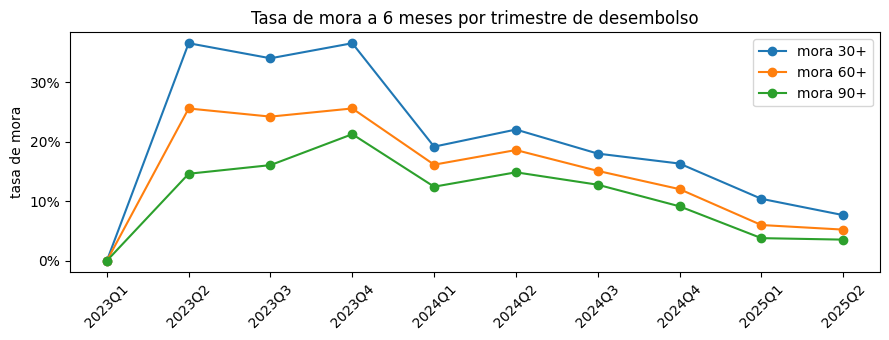

In [22]:
pob["trimestre"] = pob["fecha_desembolso"].dt.to_period("Q").astype(str)
t = pob.groupby("trimestre").agg(creditos=("mora30_6m", "size"), mora30=("mora30_6m", "mean"),
                                 mora60=("mora60_6m", "mean"), mora90=("mora90_6m", "mean"))
display(t.T)
fig, ax = plt.subplots(figsize=(9, 3.5))
for c in ["mora30", "mora60", "mora90"]:
    ax.plot(t.index, t[c], marker="o", label=c.replace("mora", "mora ") + "+")
ax.set(title="Tasa de mora a 6 meses por trimestre de desembolso", ylabel="tasa de mora")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [23]:
# ¿La baja se explica por un cambio en el perfil de los clientes? Se compara la mora DENTRO de cada categoría
pd.concat({
    "aprobación": pob.pivot_table(index="ref_aprobacion", columns="anio", values="mora30_6m"),
    "tipo de independiente": pob.pivot_table(index="independiente_informal", columns="anio", values="mora30_6m"),
    "tipo de uso": pob.pivot_table(index="tipo_uso_moto", columns="anio", values="mora30_6m"),
}).style.format("{:.0%}", na_rep="-")

**Lectura:** entre 2023 y 2025 la mora cae en **todas** las categorías (entre 2024 y 2025 solo la de uso urbano y de trabajo no baja), así que la caída no se explica por un cambio en la mezcla de clientes. Coincide con cambios en las condiciones de aprobación (prenda, cuota inicial, plazo, tasa), que se muestran en el notebook 06. Consecuencias para el modelado:
- escoger variables y versiones solo con 2023–2024 y usar 2025 solo para la evaluación final;
- medir la discriminación **dentro de cada cosecha**, para no premiar a las variables que solo distinguen el año;
- reportar la calibración por año y recalibrar el nivel de la probabilidad.

### 6.2 Mora 30+ por variable (descriptivo)

Incluye el sexo, que no entra al modelo, porque se usa en la auditoría de equidad.

In [24]:
def tasa(var):
    return pob.groupby(var, dropna=False, observed=True)["mora30_6m"].agg(creditos="size", mora30="mean").sort_values("mora30", ascending=False)

pob["rango_edad"] = pd.cut(pob["edad"], [17, 23, 28, 34, 40, 50, 90], labels=["18-23", "24-28", "29-34", "35-40", "41-50", "51+"])
pob["rango_precio"] = pd.qcut(pob["precio_moto"].rank(method="first"), 4, labels=["Q1 más barata", "Q2", "Q3", "Q4 más cara"])
for v in ["sexo", "rango_edad", "estado_civil", "estrato", "personas_a_cargo", "nivel_estudio",
          "independiente_informal", "tipo_uso_moto", "rango_precio", "propietario_moto_cliente", "zona_homologada"]:
    display(tasa(v).T.rename_axis(v, axis=1))

sexo,M,F
creditos,"1,838.000","1,070.000"
mora30,0.207,0.137


rango_edad,51+,18-23,41-50,29-34,24-28,35-40
creditos,364.000,311.000,544.000,657.000,458.000,574.000
mora30,0.220,0.212,0.180,0.178,0.166,0.159


estado_civil,VIUDO,SEPARADO,SOLTERO,UNION LIBRE,CASADO,NaN
creditos,11.000,23.000,"1,627.000",708.000,537.000,2.000
mora30,0.364,0.348,0.209,0.145,0.136,0.000


estrato,5.000,3.000,4.000,6.000,2.000,1.000
creditos,359.000,918.000,"1,259.000",96.000,273.000,3.000
mora30,0.214,0.187,0.178,0.177,0.139,0.000


personas_a_cargo,NaN,5.000,0.000,1.000,2.000,3.000,4.000,6.000
creditos,1.000,2.000,"2,030.000",569.000,253.000,39.000,12.000,2.000
mora30,1.000,0.500,0.197,0.149,0.142,0.128,0.083,0.000


nivel_estudio,PRIMARIA,BACHILLER,PREGRADO,POSTGRADO,SIN ESTUDIO
creditos,95.000,"1,324.000","1,011.000",476.000,2.000
mora30,0.211,0.190,0.185,0.147,0.000


independiente_informal,1,0
creditos,545.000,"2,363.000"
mora30,0.231,0.170


tipo_uso_moto,DOBLE_PROPOSITO,NAKED_SPORT,URBANA_TRABAJO,SCOOTER,ATV
creditos,708.000,597.000,448.000,"1,154.000",1.000
mora30,0.240,0.216,0.210,0.117,0.000


rango_precio,Q3,Q1 más barata,Q2,Q4 más cara
creditos,727.000,727.000,727.000,727.000
mora30,0.217,0.199,0.162,0.147


propietario_moto_cliente,1,0
creditos,"2,612.000",296.000
mora30,0.182,0.179


zona_homologada,NaN,Z06 CUNDINAMARCA/ BOYACA/ META,Z05 ANTIOQUIA/ CAQUETA,Z08 MONTERIA/ URABA/ BAJO CAUCA/ PUTUMAYO,Z04 EJE CAFETERO/ TOLIMA,Z02 SANTANDERES/ CESAR/ BOLIVAR/ ATLANTICO,Z03 VALLE/ CAUCA/ HUILA/ NARINO
creditos,40.000,547.000,"1,038.000",97.000,351.000,413.000,422.000
mora30,0.350,0.243,0.197,0.175,0.174,0.123,0.114


### 6.3 Línea base: el segmento actual

In [25]:
tasa("ref_segmento")

,creditos,mora30
ref_segmento,,
BRONCE,2395,0.186
ORO,99,0.162
PLATA,414,0.159


El segmento Bronce concentra el 82,4 % de los créditos con resultado (2.395 de 2.908), y la mora es de 18,6 % en Bronce, 15,9 % en Plata y 16,2 % en Oro: el segmento de menor riesgo no tiene la menor mora. La calificación actual discrimina poco en esta población. Esa es la referencia contra la que se comparará el modelo, sin usarla como variable.